# Mini Projeto Integrador - Parte 2: Análise Multidomínio de um Sinal e de um Sistema

## Visão Geral e Aplicação Escolhida
Neste notebook, desenvolvemos a aplicação computacional completa do **Mini Projeto Integrador - Parte 2**, que integra análises no **Domínio do Tempo**, **Domínio da Frequência (FFT/Janelamento)**, **Plano-s (Laplace)** e **Plano-z (Transformada-Z)**.

- **Aplicação de Engenharia (Etapa 1)**: Monitoramento da vibração mecânica de um motor elétrico industrial acoplado a um mancal de rolamento.
- **Sinal de Vibração**: Combinação da vibração fundamental do eixo giratório ($f_1 = 30\text{ Hz}$, referente a $1800\text{ RPM}$) com uma componente de alta frequência decorrente de um início de falha na pista do rolamento ($f_2 = 120\text{ Hz}$).
- **Modelo de Sistema**: Sistema mecânico de 2ª ordem subamortecido (massa-mola-amortecedor) representando a dinâmica do suporte do mancal.

In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Garantir a criação do diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## Etapas 2 e 3: Geração do Sinal e Amostragem (Nyquist)

- **Sinal Analógico Simulado $x(t)$**:
  $$x(t) = A_1 \cos(2\pi f_1 t + \phi_1) + A_2 \cos(2\pi f_2 t + \phi_2)$$
  Com $A_1 = 1.0\text{ V}$, $f_1 = 30\text{ Hz}$, $A_2 = 0.6\text{ V}$, $f_2 = 120\text{ Hz}$, $\phi_1 = 0$ e $\phi_2 = \pi/4$.
- **Critério de Nyquist e Amostragem**:
  A maior frequência presente é $f_{\max} = 120\text{ Hz}$. Pelo Teorema de Nyquist, exige-se $f_s > 2 f_{\max} = 240\text{ Hz}$. Escolhemos **$f_s = 500\text{ Hz}$** ($T_s = 2.0\text{ ms}$), garantindo uma amostragem adequada sem aliasing.

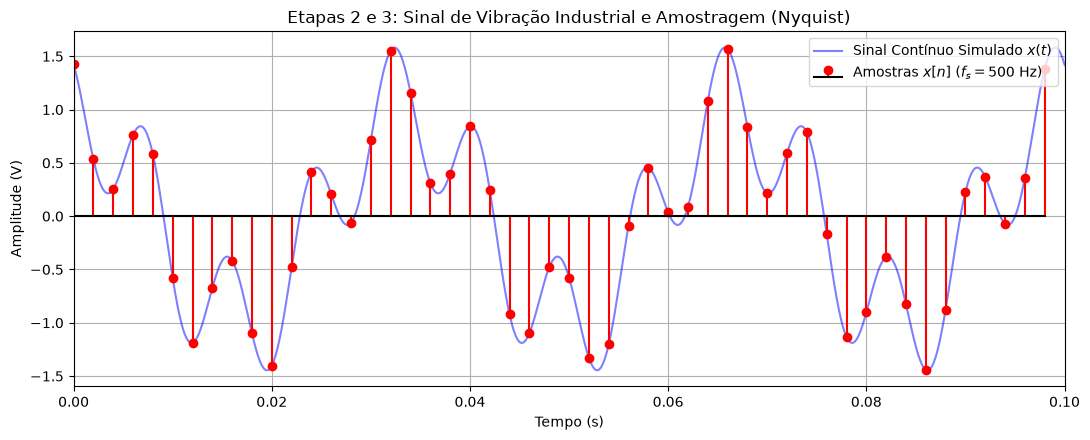

In [10]:
# Parâmetros do Sinal
f1, f2 = 30.0, 120.0       # Frequências em Hz
A1, A2 = 1.0, 0.6          # Amplitudes
phi1, phi2 = 0.0, np.pi/4  # Fases

# Intervalo de observação temporal
T_obs = 1.0                # 1 segundo de dados
fs_ok = 500.0              # Frequência de amostragem adequada (fs > 240 Hz)

# Sinal Contínuo Simulado (alta resolução)
t_cont = np.linspace(0, T_obs, 5000)
x_cont = A1 * np.cos(2 * np.pi * f1 * t_cont + phi1) + A2 * np.cos(2 * np.pi * f2 * t_cont + phi2)

# Sinal Amostrado x[n]
N_ok = int(fs_ok * T_obs)
n_ok = np.arange(N_ok)
t_amost = n_ok / fs_ok
x_amost = A1 * np.cos(2 * np.pi * f1 * t_amost + phi1) + A2 * np.cos(2 * np.pi * f2 * t_amost + phi2)

# Plotagem temporal
fig1, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.plot(t_cont, x_cont, 'b-', alpha=0.5, label=r'Sinal Contínuo Simulado $x(t)$')
ax1.stem(t_amost[:50], x_amost[:50], linefmt='r-', markerfmt='ro', basefmt='k-', label=r'Amostras $x[n]$ ($f_s = 500\text{ Hz}$)')
ax1.set_title('Etapas 2 e 3: Sinal de Vibração Industrial e Amostragem (Nyquist)')
ax1.set_xlabel('Tempo (s)')
ax1.set_ylabel('Amplitude (V)')
ax1.set_xlim(0, 0.1)
ax1.grid(True)
ax1.legend(loc='upper right')

plt.tight_layout()
fig1.savefig("grafico_mini_projeto_amostragem.png")
plt.show()

## Etapa 4: Análise Espectral via FFT

Calculamos a FFT da sequência amostrada de $N = 500$ pontos.
- **Resolução Espectral ($\Delta f$)**:
  $$\Delta f = \frac{f_s}{N} = \frac{500}{500} = 1.0\text{ Hz}$$
- As componentes espectrais devem surgir exatamente em **$30\text{ Hz}$** (amplitude $1.0$) e **$120\text{ Hz}$** (amplitude $0.6$).

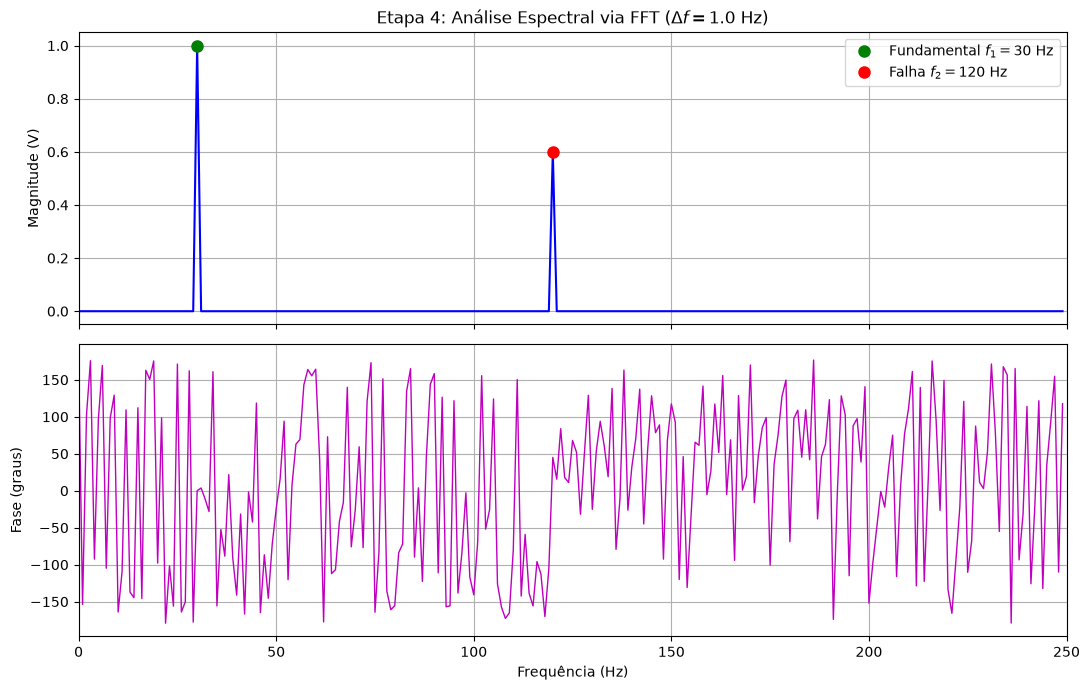

In [11]:
# Cálculo da FFT
X_fft = np.fft.fft(x_amost)
freqs = np.fft.fftfreq(N_ok, 1/fs_ok)

# Apenas metade positiva do espectro
idx_pos = np.arange(N_ok // 2)
freqs_pos = freqs[idx_pos]
mag_pos = np.abs(X_fft[idx_pos]) / (N_ok / 2)
fase_pos = np.angle(X_fft[idx_pos])

fig2, (ax_mag, ax_fase) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# Espectro de Magnitude
ax_mag.plot(freqs_pos, mag_pos, 'b-', linewidth=1.5)
ax_mag.plot(f1, A1, 'go', markersize=8, label=r'Fundamental $f_1 = 30\text{ Hz}$')
ax_mag.plot(f2, A2, 'ro', markersize=8, label=r'Falha $f_2 = 120\text{ Hz}$')
ax_mag.set_title(r'Etapa 4: Análise Espectral via FFT ($\Delta f = 1.0\text{ Hz}$)')
ax_mag.set_ylabel('Magnitude (V)')
ax_mag.grid(True)
ax_mag.legend(loc='upper right')

# Espectro de Fase
ax_fase.plot(freqs_pos, np.degrees(fase_pos), 'm-', linewidth=1.0)
ax_fase.set_xlabel('Frequência (Hz)')
ax_fase.set_ylabel('Fase (graus)')
ax_fase.set_xlim(0, 250)
ax_fase.grid(True)

plt.tight_layout()
fig2.savefig("grafico_mini_projeto_espectro.png")
plt.show()

## Etapa 5: Investigação de Aliasing (Subamostragem)

Reduzimos a frequência de amostragem para **$f_s = 180\text{ Hz}$**, violando o critério de Nyquist ($f_{\text{Nyquist}} = 90\text{ Hz} < f_2 = 120\text{ Hz}$).
- A componente de $120\text{ Hz}$ sofre aliasing e reaparece na frequência aparente:
  $$f_{\text{alias}} = |f_2 - f_s| = |120 - 180| = 60\text{ Hz}$$

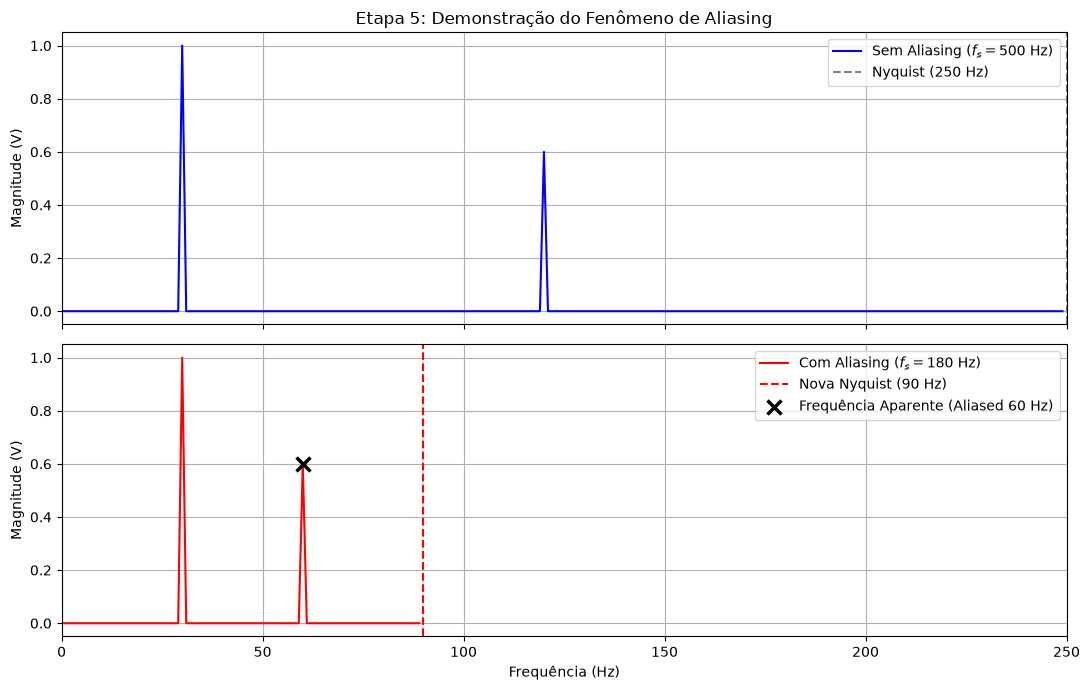

In [12]:
# Amostragem com Aliasing (fs = 180 Hz)
fs_alias = 180.0
N_alias = int(fs_alias * T_obs)
n_alias = np.arange(N_alias)
t_alias = n_alias / fs_alias
x_alias = A1 * np.cos(2 * np.pi * f1 * t_alias + phi1) + A2 * np.cos(2 * np.pi * f2 * t_alias + phi2)

# FFT do sinal com Aliasing
X_fft_alias = np.fft.fft(x_alias)
freqs_alias = np.fft.fftfreq(N_alias, 1/fs_alias)
idx_pos_alias = np.arange(N_alias // 2)

freqs_pos_alias = freqs_alias[idx_pos_alias]
mag_alias = np.abs(X_fft_alias[idx_pos_alias]) / (N_alias / 2)

fig3, (ax_ok, ax_al) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# Espectro sem Aliasing
ax_ok.plot(freqs_pos, mag_pos, 'b-', linewidth=1.5, label=r'Sem Aliasing ($f_s = 500\text{ Hz}$)')
ax_ok.axvline(250, color='gray', linestyle='--', label=r'Nyquist ($250\text{ Hz}$)')
ax_ok.set_title('Etapa 5: Demonstração do Fenômeno de Aliasing')
ax_ok.set_ylabel('Magnitude (V)')
ax_ok.grid(True)
ax_ok.legend(loc='upper right')

# Espectro com Aliasing
ax_al.plot(freqs_pos_alias, mag_alias, 'r-', linewidth=1.5, label=r'Com Aliasing ($f_s = 180\text{ Hz}$)')
ax_al.axvline(90, color='red', linestyle='--', label=r'Nova Nyquist ($90\text{ Hz}$)')
ax_al.plot(60, A2, 'kx', markersize=10, markeredgewidth=2.5, label=r'Frequência Aparente (Aliased $60\text{ Hz}$)')
ax_al.set_xlabel('Frequência (Hz)')
ax_al.set_ylabel('Magnitude (V)')
ax_al.set_xlim(0, 250)
ax_al.grid(True)
ax_al.legend(loc='upper right')

plt.tight_layout()
fig3.savefig("grafico_mini_projeto_aliasing.png")
plt.show()

## Etapa 6: Efeito de Janelamento e Vazamento Espectral

Para investigar o vazamento espectral (*spectral leakage*), escolhemos um sinal com frequência desalinhada dos *bins* da DFT ($f_0 = 33.3\text{ Hz}$).
Comparamos a janela **Retangular** (sem janela adicional), **Hann** e **Hamming**:
- **Janela Retangular**: Lóbulo principal estreito, mas lóbulos laterais altos (elevado vazamento).
- **Janela Hann / Hamming**: Atenuam fortemente os lóbulos laterais às custas de um ligeiro alargamento do lóbulo principal.

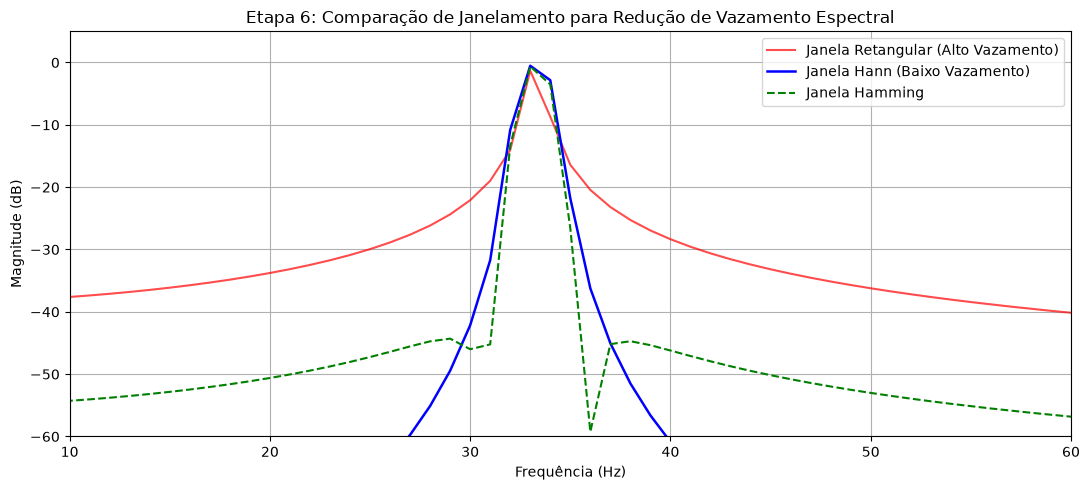

In [13]:
# Sinal desalinhado do bin
f_off = 33.3
x_off = np.cos(2 * np.pi * f_off * t_amost)

# Funções Janela
w_rect = np.ones(N_ok)
w_hann = np.hanning(N_ok)
w_hamm = np.hamming(N_ok)

# Aplicação e FFT
X_rect = np.fft.fft(x_off * w_rect)
X_hann = np.fft.fft(x_off * w_hann) * 2.0  # Correção de ganho coerente
X_hamm = np.fft.fft(x_off * w_hamm) * 1.85

mag_rect = 20 * np.log10(np.maximum(np.abs(X_rect[idx_pos]) / (N_ok / 2), 1e-4))
mag_hann = 20 * np.log10(np.maximum(np.abs(X_hann[idx_pos]) / (N_ok / 2), 1e-4))
mag_hamm = 20 * np.log10(np.maximum(np.abs(X_hamm[idx_pos]) / (N_ok / 2), 1e-4))

fig4, ax_win = plt.subplots(figsize=(11, 5))
ax_win.plot(freqs_pos, mag_rect, 'r-', alpha=0.7, label='Janela Retangular (Alto Vazamento)')
ax_win.plot(freqs_pos, mag_hann, 'b-', linewidth=1.8, label='Janela Hann (Baixo Vazamento)')
ax_win.plot(freqs_pos, mag_hamm, 'g--', linewidth=1.5, label='Janela Hamming')
ax_win.set_title('Etapa 6: Comparação de Janelamento para Redução de Vazamento Espectral')
ax_win.set_xlabel('Frequência (Hz)')
ax_win.set_ylabel('Magnitude (dB)')
ax_win.set_xlim(10, 60)
ax_win.set_ylim(-60, 5)
ax_win.grid(True)
ax_win.legend(loc='upper right')

plt.tight_layout()
fig4.savefig("grafico_mini_projeto_janelamento.png")
plt.show()

## Etapa 7: Modelo Contínuo no Domínio de Laplace (Plano-$s$)

Modelamos o suporte mecânico do mancal como um sistema contínuo de 2ª ordem:
$$H(s) = \frac{\omega_n^2}{s^2 + 2\zeta\omega_n s + \omega_n^2}$$

Com frequência natural $\omega_n = 2\pi \times 50\text{ rad/s} \approx 314.16\text{ rad/s}$ e fator de amortecimento $\zeta = 0.2$ (sistema subamortecido).
- **Polos do Sistema**:
  $$p_{1,2} = -\zeta\omega_n \pm j\omega_n\sqrt{1-\zeta^2} = -62.83 \pm j 307.81\text{ rad/s}$$
  Como $\text{Re}\{p_{1,2}\} = -62.83 < 0$, o sistema contínuo é **BIBO e assintoticamente estável**.

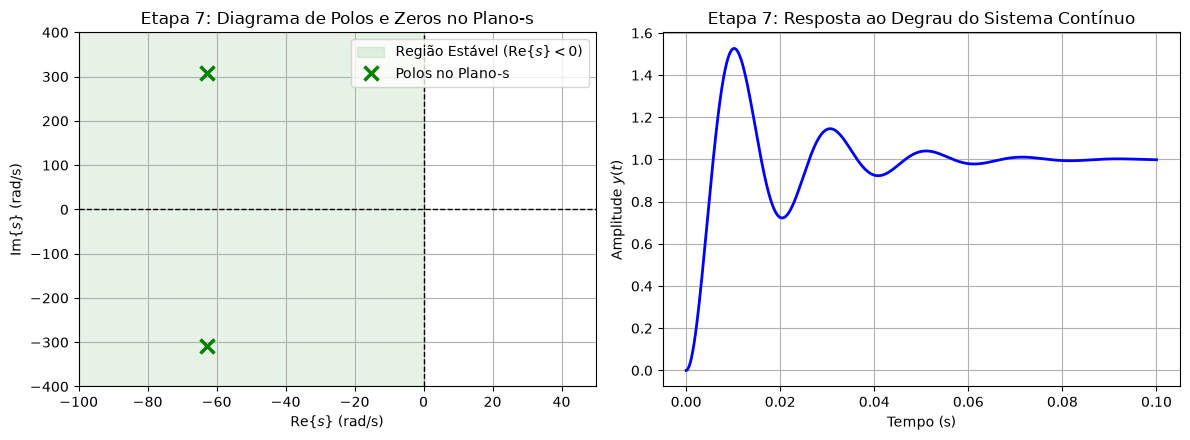

In [14]:
wn = 2 * np.pi * 50.0
zeta = 0.2

# Função de transferência contínua
num_s = [wn**2]
den_s = [1.0, 2 * zeta * wn, wn**2]
sys_s = signal.lti(num_s, den_s)
polos_s = sys_s.poles

# Resposta ao degrau contínuo
t_s, y_s = signal.step(sys_s, T=np.linspace(0, 0.1, 1000))

fig5, (ax_pz_s, ax_step_s) = plt.subplots(1, 2, figsize=(12, 4.5))

# Mapa de Polos e Zeros no Plano-s
ax_pz_s.axhline(0, color='black', linestyle='--', linewidth=1)
ax_pz_s.axvline(0, color='black', linestyle='--', linewidth=1)
ax_pz_s.axvspan(-400, 0, color='green', alpha=0.1, label=r'Região Estável ($\text{Re}\{s\} < 0$)')
ax_pz_s.plot(np.real(polos_s), np.imag(polos_s), 'gx', markersize=10, markeredgewidth=2.5, label='Polos no Plano-s')
ax_pz_s.set_title('Etapa 7: Diagrama de Polos e Zeros no Plano-s')
ax_pz_s.set_xlabel(r'$\text{Re}\{s\}$ (rad/s)')
ax_pz_s.set_ylabel(r'$\text{Im}\{s\}$ (rad/s)')
ax_pz_s.set_xlim(-100, 50)
ax_pz_s.set_ylim(-400, 400)
ax_pz_s.grid(True)
ax_pz_s.legend(loc='upper right')

# Resposta Temporal ao Degrau
ax_step_s.plot(t_s, y_s, 'b-', linewidth=2)
ax_step_s.set_title('Etapa 7: Resposta ao Degrau do Sistema Contínuo')
ax_step_s.set_xlabel('Tempo (s)')
ax_step_s.set_ylabel('Amplitude $y(t)$')
ax_step_s.grid(True)

plt.tight_layout()
fig5.savefig("grafico_mini_projeto_plano_s.png")
plt.show()

## Etapa 8: Modelo Discreto na Transformada-Z (Plano-$z$)

Obtemos a representação discreta equivalente $H(z)$ para período de amostragem $T_s = 2.0\text{ ms}$ ($f_s = 500\text{ Hz}$).
- **Polos no Plano-$z$**:
  $$p_z = e^{p_s T_s} = e^{(-62.83 \pm j 307.81) \times 0.002} = 0.7200 \pm j 0.5093$$
- **Módulo dos Polos**:
  $$|p_z| = e^{-62.83 \times 0.002} = e^{-0.1257} \approx 0.8819$$
  Como $|p_z| = 0.8819 < 1.0$, todos os polos estão **estritamente dentro do círculo unitário**, confirmando a estabilidade BIBO no domínio discreto.

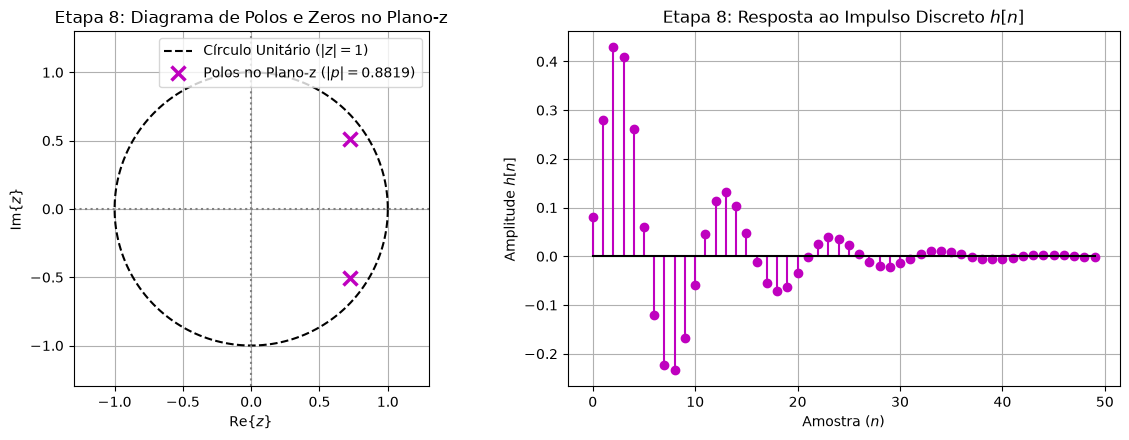

In [15]:
Ts = 1 / fs_ok

# Mapeamento dos polos para o domínio discreto via z = exp(s * Ts)
polos_z_exp = np.exp(polos_s * Ts)

# Discretização da função de transferência via amostragem / transformada bilinear
sys_z = signal.cont2discrete((num_s, den_s), Ts, method='bilinear')
b_z, a_z = sys_z[0][0], sys_z[1]
sys_dlti = signal.dlti(b_z, a_z)

# Resposta ao impulso discreto
t_z_out, h_z_out = signal.dlsim(sys_dlti, np.eye(50, 1).flatten())

fig6, (ax_pz_z, ax_imp_z) = plt.subplots(1, 2, figsize=(12, 4.5))

# Mapa de Polos e Zeros no Plano-z
theta = np.linspace(0, 2 * np.pi, 200)
ax_pz_z.plot(np.cos(theta), np.sin(theta), 'k--', label='Círculo Unitário ($|z|=1$)')
ax_pz_z.axhline(0, color='gray', linestyle=':')
ax_pz_z.axvline(0, color='gray', linestyle=':')
ax_pz_z.plot(np.real(polos_z_exp), np.imag(polos_z_exp), 'mx', markersize=10, markeredgewidth=2.5, label='Polos no Plano-z ($|p|=0.8819$)')
ax_pz_z.set_title('Etapa 8: Diagrama de Polos e Zeros no Plano-z')
ax_pz_z.set_xlabel(r'$\text{Re}\{z\}$')
ax_pz_z.set_ylabel(r'$\text{Im}\{z\}$')
ax_pz_z.set_xlim(-1.3, 1.3)
ax_pz_z.set_ylim(-1.3, 1.3)
ax_pz_z.set_aspect('equal')
ax_pz_z.grid(True)
ax_pz_z.legend(loc='upper right')

# Resposta ao Impulso Discreto
ax_imp_z.stem(np.arange(50), np.squeeze(h_z_out), linefmt='m-', markerfmt='mo', basefmt='k-')
ax_imp_z.set_title('Etapa 8: Resposta ao Impulso Discreto $h[n]$')
ax_imp_z.set_xlabel('Amostra ($n$)')
ax_imp_z.set_ylabel('Amplitude $h[n]$')
ax_imp_z.grid(True)

plt.tight_layout()
fig6.savefig("grafico_mini_projeto_plano_z.png")
plt.show()

## Etapa 9: Relação de Mapeamento entre os Planos ($s \to z$)

Visualizamos graficamente a correspondência direta dada por $z = e^{s T_s}$:
- **Semiplano Esquerdo ($\text{Re}\{s\} < 0$)** $\longrightarrow$ **Interior do Círculo Unitário ($|z| < 1$)**.
- O polo contínuo em $s = -62.83 \pm j 307.81$ é mapeado exatamente sobre o polo discreto de módulo $r = 0.8819$ e ângulo $\Omega = \omega T_s = 0.6156\text{ rad/amostra}$.

<>:6: SyntaxWarning: invalid escape sequence '\o'
<>:6: SyntaxWarning: invalid escape sequence '\o'
C:\Users\tacit\AppData\Local\Temp\ipykernel_34944\2762093069.py:6: SyntaxWarning: invalid escape sequence '\o'
  ax_s_map.axvline(0, color='blue', linestyle='--', linewidth=1.5, label='Eixo $j\omega$')


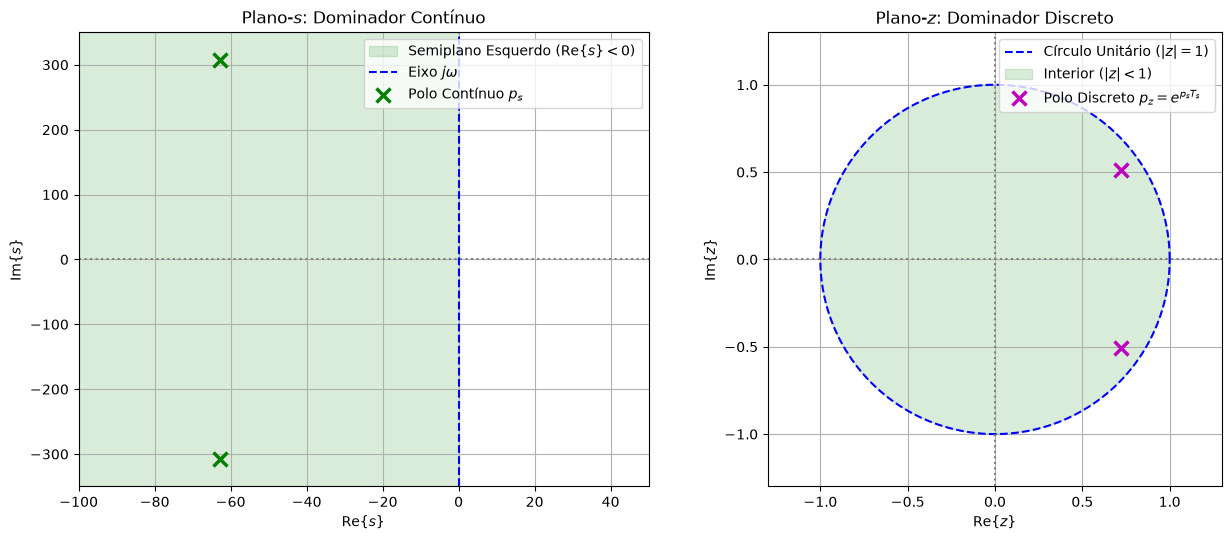

In [16]:
fig7, (ax_s_map, ax_z_map) = plt.subplots(1, 2, figsize=(13, 5.5))

# Plano-s
ax_s_map.axvspan(-200, 0, color='green', alpha=0.15, label=r'Semiplano Esquerdo ($\text{Re}\{s\} < 0$)')
ax_s_map.axhline(0, color='gray', linestyle=':')
ax_s_map.axvline(0, color='blue', linestyle='--', linewidth=1.5, label='Eixo $j\omega$')
ax_s_map.plot(np.real(polos_s), np.imag(polos_s), 'gx', markersize=10, markeredgewidth=2.5, label='Polo Contínuo $p_s$')
ax_s_map.set_title(r'Plano-$s$: Dominador Contínuo')
ax_s_map.set_xlabel(r'$\text{Re}\{s\}$')
ax_s_map.set_ylabel(r'$\text{Im}\{s\}$')
ax_s_map.set_xlim(-100, 50)
ax_s_map.set_ylim(-350, 350)
ax_s_map.grid(True)
ax_s_map.legend(loc='upper right')

# Plano-z
ax_z_map.plot(np.cos(theta), np.sin(theta), 'b--', linewidth=1.5, label='Círculo Unitário ($|z|=1$)')
ax_z_map.fill(np.cos(theta), np.sin(theta), color='green', alpha=0.15, label=r'Interior ($|z| < 1$)')
ax_z_map.axhline(0, color='gray', linestyle=':')
ax_z_map.axvline(0, color='gray', linestyle=':')
ax_z_map.plot(np.real(polos_z_exp), np.imag(polos_z_exp), 'mx', markersize=10, markeredgewidth=2.5, label=r'Polo Discreto $p_z = e^{p_s T_s}$')
ax_z_map.set_title(r'Plano-$z$: Dominador Discreto')
ax_z_map.set_xlabel(r'$\text{Re}\{z\}$')
ax_z_map.set_ylabel(r'$\text{Im}\{z\}$')
ax_z_map.set_xlim(-1.3, 1.3)
ax_z_map.set_ylim(-1.3, 1.3)
ax_z_map.set_aspect('equal')
ax_z_map.grid(True)
ax_z_map.legend(loc='upper right')

plt.tight_layout()
fig7.savefig("grafico_mini_projeto_mapeamento.png")
plt.show()

## Etapa 10: Síntese e Conclusões da Análise Multidomínio
- **Integração dos Domínios**:
  - O **Tempo** revela a evolução dinâmica e as oscilações transientes.
  - A **Frequência (FFT)** isola as componentes de vibração ($30\text{ Hz}$ do eixo e $120\text{ Hz}$ da falha no rolamento).
  - O **Plano-$s$** expressa os parâmetros físicos do sistema ($\omega_n$, $\zeta$).
  - O **Plano-$z$** fornece o algoritmo discreto exato para implementação em tempo real em processadores e DSPs.